In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import time

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("GPU available:", torch.cuda.is_available())

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

class ResNet18_CIFAR(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        base = torchvision.models.resnet18(weights=None, num_classes=num_classes)
        base.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        base.maxpool = nn.Identity()
        self.model = base
    def forward(self, x):
        return self.model(x)

print("Setup ready, starting training...")

model = ResNet18_CIFAR().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):
    model.train()
    running_loss = 0.0
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}/20, Loss: {running_loss/len(trainloader):.3f}")

model.eval()
correct = total = 0
with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f"Baseline accuracy: {100*correct/total:.2f}%")

GPU available: True


100%|██████████| 170M/170M [20:48<00:00, 137kB/s]  


Setup ready, starting training...
Epoch 1/20, Loss: 1.343
Epoch 2/20, Loss: 0.856
Epoch 3/20, Loss: 0.668
Epoch 4/20, Loss: 0.562
Epoch 5/20, Loss: 0.495
Epoch 6/20, Loss: 0.435
Epoch 7/20, Loss: 0.391
Epoch 8/20, Loss: 0.355
Epoch 9/20, Loss: 0.329
Epoch 10/20, Loss: 0.302
Epoch 11/20, Loss: 0.282
Epoch 12/20, Loss: 0.258
Epoch 13/20, Loss: 0.238
Epoch 14/20, Loss: 0.225
Epoch 15/20, Loss: 0.204
Epoch 16/20, Loss: 0.191
Epoch 17/20, Loss: 0.178
Epoch 18/20, Loss: 0.166
Epoch 19/20, Loss: 0.160
Epoch 20/20, Loss: 0.145
Baseline accuracy: 89.99%


In [4]:
def perturb_image(pixels, image):
    img = image.clone()
    num_pixels = len(pixels) // 5
    for p in range(num_pixels):
        x, y, r, g, b = pixels[p*5:(p+1)*5]
        x = int(x * 31)
        y = int(y * 31)
        img[0, x, y] = (r - mean[0]) / std[0]
        img[1, x, y] = (g - mean[1]) / std[1]
        img[2, x, y] = (b - mean[2]) / std[2]
    return img

def predict_confidence(model, image, true_label):
    with torch.no_grad():
        image_t = image.unsqueeze(0).to(device)
        output = torch.softmax(model(image_t), dim=1)
        return output[0, true_label].item(), output[0].argmax().item()

def differential_evolution_attack(model, image, true_label, num_pixels=1, pop_size=400, max_iter=75, F=0.5, CR=0.7):
    dim = num_pixels * 5
    population = np.random.rand(pop_size, dim)

    def fitness(pixels):
        perturbed = perturb_image(pixels, image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        return conf

    fitness_values = np.array([fitness(ind) for ind in population])

    for generation in range(max_iter):
        for i in range(pop_size):
            idxs = [idx for idx in range(pop_size) if idx != i]
            a, b, c = population[np.random.choice(idxs, 3, replace=False)]
            mutant = np.clip(a + F * (b - c), 0, 1)
            trial = population[i].copy()
            cross_points = np.random.rand(dim) < CR
            trial[cross_points] = mutant[cross_points]
            trial_fitness = fitness(trial)
            if trial_fitness < fitness_values[i]:
                population[i] = trial
                fitness_values[i] = trial_fitness

        best_idx = np.argmin(fitness_values)
        perturbed = perturb_image(population[best_idx], image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        if pred != true_label:
            return True, generation, population[best_idx], conf

    best_idx = np.argmin(fitness_values)
    return False, max_iter, population[best_idx], fitness_values[best_idx]

print("Baseline DE attack function ready")

Baseline DE attack function ready


In [5]:
test_images = []
test_labels_list = []
for images, labels in testloader:
    for i in range(len(images)):
        test_images.append(images[i])
        test_labels_list.append(labels[i].item())
    if len(test_images) >= 20:
        break

test_images = test_images[:20]
test_labels_list = test_labels_list[:20]

start = time.time()
success_count = 0
results_baseline = []
for i in range(20):
    success, gens, best_pixels, final_conf = differential_evolution_attack(
        model, test_images[i], test_labels_list[i], num_pixels=1, pop_size=400, max_iter=75
    )
    results_baseline.append((success, gens, final_conf))
    if success:
        success_count += 1
    print(f"Image {i}: true={classes[test_labels_list[i]]}, success={success}, gens={gens}, conf={final_conf:.3f}")

elapsed = time.time() - start
print(f"\nBaseline success rate: {success_count}/20 = {success_count*5}%")
print(f"Time: {elapsed/60:.1f} min")

Image 0: true=cat, success=False, gens=75, conf=0.989
Image 1: true=ship, success=False, gens=75, conf=0.973
Image 2: true=ship, success=False, gens=75, conf=0.671
Image 3: true=plane, success=True, gens=0, conf=0.031
Image 4: true=frog, success=False, gens=75, conf=0.897
Image 5: true=frog, success=False, gens=75, conf=0.999
Image 6: true=car, success=False, gens=75, conf=0.967
Image 7: true=frog, success=False, gens=75, conf=0.949
Image 8: true=cat, success=False, gens=75, conf=0.920
Image 9: true=car, success=True, gens=0, conf=0.133
Image 10: true=plane, success=True, gens=15, conf=0.260
Image 11: true=truck, success=False, gens=75, conf=1.000
Image 12: true=dog, success=False, gens=75, conf=0.966
Image 13: true=horse, success=False, gens=75, conf=0.991
Image 14: true=truck, success=False, gens=75, conf=1.000
Image 15: true=ship, success=True, gens=0, conf=0.002
Image 16: true=dog, success=False, gens=75, conf=0.801
Image 17: true=horse, success=False, gens=75, conf=0.937
Image 18:

In [6]:
class SurrogateNet(nn.Module):
    def __init__(self, input_dim=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        return self.net(x)

def dl_guided_de_attack(model, image, true_label, num_pixels=1, pop_size=400, max_iter=75, F=0.5, CR=0.7,
                          surrogate_train_freq=5):
    dim = num_pixels * 5
    population = np.random.rand(pop_size, dim)

    surrogate = SurrogateNet(dim).to(device)
    surrogate_optimizer = optim.Adam(surrogate.parameters(), lr=0.01)

    def fitness(pixels):
        perturbed = perturb_image(pixels, image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        return conf

    fitness_values = np.array([fitness(ind) for ind in population])
    history_X, history_y = list(population), list(fitness_values)
    real_queries = len(population)

    for generation in range(max_iter):
        if generation % surrogate_train_freq == 0 and len(history_X) > 20:
            X_t = torch.FloatTensor(np.array(history_X)).to(device)
            y_t = torch.FloatTensor(np.array(history_y)).unsqueeze(1).to(device)
            for _ in range(20):
                surrogate_optimizer.zero_grad()
                pred = surrogate(X_t)
                loss = nn.functional.mse_loss(pred, y_t)
                loss.backward()
                surrogate_optimizer.step()

        for i in range(pop_size):
            idxs = [idx for idx in range(pop_size) if idx != i]
            a, b, c = population[np.random.choice(idxs, 3, replace=False)]
            mutant = np.clip(a + F * (b - c), 0, 1)
            trial = population[i].copy()
            cross_points = np.random.rand(dim) < CR
            trial[cross_points] = mutant[cross_points]

            with torch.no_grad():
                trial_t = torch.FloatTensor(trial).unsqueeze(0).to(device)
                predicted_conf = surrogate(trial_t).item()

            if predicted_conf < fitness_values[i] or generation < surrogate_train_freq:
                trial_fitness = fitness(trial)
                real_queries += 1
                history_X.append(trial.copy())
                history_y.append(trial_fitness)
                if trial_fitness < fitness_values[i]:
                    population[i] = trial
                    fitness_values[i] = trial_fitness

        best_idx = np.argmin(fitness_values)
        perturbed = perturb_image(population[best_idx], image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        real_queries += 1
        if pred != true_label:
            return True, generation, population[best_idx], conf, real_queries

    best_idx = np.argmin(fitness_values)
    return False, max_iter, population[best_idx], fitness_values[best_idx], real_queries

print("DL-guided DE attack function ready")

DL-guided DE attack function ready


In [7]:
start = time.time()
success_count_dl = 0
results_dl = []
for i in range(20):
    success, gens, best_pixels, final_conf, real_queries = dl_guided_de_attack(
        model, test_images[i], test_labels_list[i], num_pixels=1, pop_size=400, max_iter=75
    )
    results_dl.append((success, gens, final_conf, real_queries))
    if success:
        success_count_dl += 1
    print(f"Image {i}: true={classes[test_labels_list[i]]}, success={success}, gens={gens}, conf={final_conf:.3f}, real_queries={real_queries}")

elapsed = time.time() - start
print(f"\nDL-guided success rate: {success_count_dl}/20 = {success_count_dl*5}%")
print(f"Time: {elapsed/60:.1f} min")

total_queries_dl = sum(r[3] for r in results_dl)
print(f"Total real-model queries used (DL-guided): {total_queries_dl}")
print(f"Average queries per image (DL-guided): {total_queries_dl/20:.0f}")

Image 0: true=cat, success=False, gens=75, conf=0.989, real_queries=14753
Image 1: true=ship, success=False, gens=75, conf=0.989, real_queries=11933
Image 2: true=ship, success=False, gens=75, conf=0.739, real_queries=8135
Image 3: true=plane, success=True, gens=0, conf=0.040, real_queries=801
Image 4: true=frog, success=False, gens=75, conf=0.901, real_queries=8209
Image 5: true=frog, success=False, gens=75, conf=0.999, real_queries=16449
Image 6: true=car, success=False, gens=75, conf=0.967, real_queries=9606
Image 7: true=frog, success=False, gens=75, conf=0.958, real_queries=9879
Image 8: true=cat, success=False, gens=75, conf=0.930, real_queries=7729
Image 9: true=car, success=True, gens=0, conf=0.070, real_queries=801
Image 10: true=plane, success=True, gens=49, conf=0.193, real_queries=6801
Image 11: true=truck, success=False, gens=75, conf=1.000, real_queries=15037
Image 12: true=dog, success=False, gens=75, conf=0.976, real_queries=9326
Image 13: true=horse, success=False, gen

In [8]:
def baseline_queries(gens, success):
    if success:
        return 400 + 400*gens + (gens+1)
    else:
        return 400 + 400*75 + 75

baseline_query_counts = [baseline_queries(gens, success) for success, gens, conf in results_baseline]
total_baseline_queries = sum(baseline_query_counts)
print(f"Baseline total queries: {total_baseline_queries}")
print(f"Baseline avg queries per image: {total_baseline_queries/20:.0f}")

print(f"\nQuery reduction from DL guidance: {100*(1 - 192116/total_baseline_queries):.1f}%")

Baseline total queries: 495219
Baseline avg queries per image: 24761

Query reduction from DL guidance: 61.2%


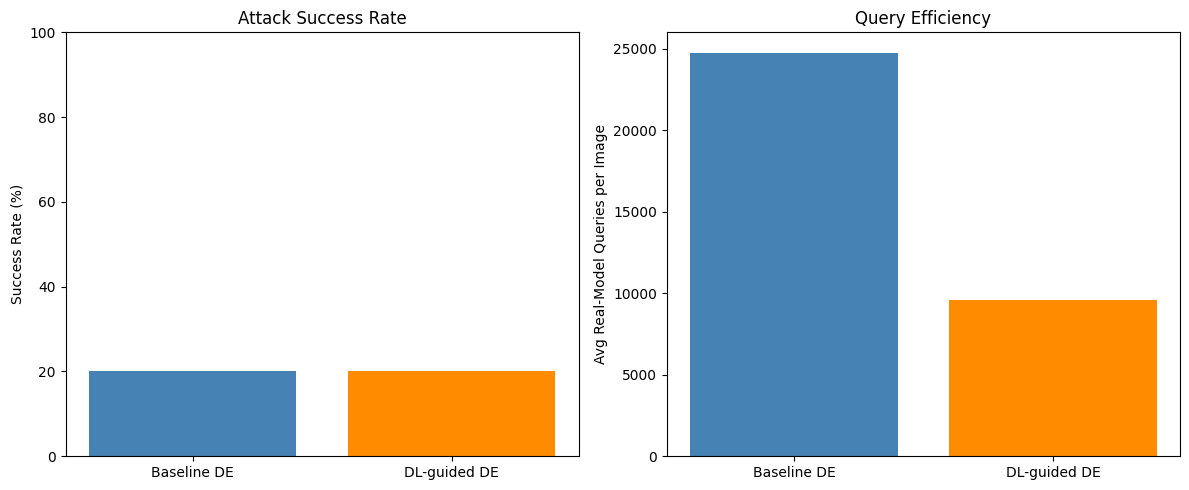

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Baseline DE', 'DL-guided DE'], [20, 20], color=['steelblue', 'darkorange'])
axes[0].set_ylabel('Success Rate (%)')
axes[0].set_title('Attack Success Rate')
axes[0].set_ylim(0, 100)

axes[1].bar(['Baseline DE', 'DL-guided DE'], [24761, 9606], color=['steelblue', 'darkorange'])
axes[1].set_ylabel('Avg Real-Model Queries per Image')
axes[1].set_title('Query Efficiency')

plt.tight_layout()
plt.show()

In [10]:
def dl_guided_de_attack_budget(model, image, true_label, num_pixels=1, pop_size=400, max_iter=300, F=0.5, CR=0.7,
                                  surrogate_train_freq=5, query_budget=25000):
    dim = num_pixels * 5
    population = np.random.rand(pop_size, dim)

    surrogate = SurrogateNet(dim).to(device)
    surrogate_optimizer = optim.Adam(surrogate.parameters(), lr=0.01)

    def fitness(pixels):
        perturbed = perturb_image(pixels, image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        return conf

    fitness_values = np.array([fitness(ind) for ind in population])
    history_X, history_y = list(population), list(fitness_values)
    real_queries = len(population)

    for generation in range(max_iter):
        if real_queries >= query_budget:
            break

        if generation % surrogate_train_freq == 0 and len(history_X) > 20:
            X_t = torch.FloatTensor(np.array(history_X)).to(device)
            y_t = torch.FloatTensor(np.array(history_y)).unsqueeze(1).to(device)
            for _ in range(20):
                surrogate_optimizer.zero_grad()
                pred = surrogate(X_t)
                loss = nn.functional.mse_loss(pred, y_t)
                loss.backward()
                surrogate_optimizer.step()

        for i in range(pop_size):
            if real_queries >= query_budget:
                break
            idxs = [idx for idx in range(pop_size) if idx != i]
            a, b, c = population[np.random.choice(idxs, 3, replace=False)]
            mutant = np.clip(a + F * (b - c), 0, 1)
            trial = population[i].copy()
            cross_points = np.random.rand(dim) < CR
            trial[cross_points] = mutant[cross_points]

            with torch.no_grad():
                trial_t = torch.FloatTensor(trial).unsqueeze(0).to(device)
                predicted_conf = surrogate(trial_t).item()

            if predicted_conf < fitness_values[i] or generation < surrogate_train_freq:
                trial_fitness = fitness(trial)
                real_queries += 1
                history_X.append(trial.copy())
                history_y.append(trial_fitness)
                if trial_fitness < fitness_values[i]:
                    population[i] = trial
                    fitness_values[i] = trial_fitness

        best_idx = np.argmin(fitness_values)
        perturbed = perturb_image(population[best_idx], image)
        conf, pred = predict_confidence(model, perturbed, true_label)
        real_queries += 1
        if pred != true_label:
            return True, generation, population[best_idx], conf, real_queries

    best_idx = np.argmin(fitness_values)
    return False, generation, population[best_idx], fitness_values[best_idx], real_queries

print("Budget-matched DL-guided attack ready")

Budget-matched DL-guided attack ready


In [11]:
start = time.time()
success_count_budget = 0
results_budget = []
for i in range(20):
    success, gens, best_pixels, final_conf, real_queries = dl_guided_de_attack_budget(
        model, test_images[i], test_labels_list[i], num_pixels=1, pop_size=400,
        max_iter=300, query_budget=25000
    )
    results_budget.append((success, gens, final_conf, real_queries))
    if success:
        success_count_budget += 1
    print(f"Image {i}: true={classes[test_labels_list[i]]}, success={success}, gens={gens}, conf={final_conf:.3f}, queries={real_queries}")

elapsed = time.time() - start
print(f"\nBudget-matched DL-guided success rate: {success_count_budget}/20 = {success_count_budget*5}%")
print(f"Time: {elapsed/60:.1f} min")

total_queries_budget = sum(r[3] for r in results_budget)
print(f"Total queries used: {total_queries_budget}")
print(f"Avg queries per image: {total_queries_budget/20:.0f}")

Image 0: true=cat, success=False, gens=299, conf=0.989, queries=17569
Image 1: true=ship, success=False, gens=299, conf=0.987, queries=13834
Image 2: true=ship, success=False, gens=299, conf=0.828, queries=8939
Image 3: true=plane, success=True, gens=0, conf=0.033, queries=801
Image 4: true=frog, success=False, gens=299, conf=0.978, queries=15026
Image 5: true=frog, success=False, gens=172, conf=0.999, queries=25001
Image 6: true=car, success=False, gens=299, conf=0.973, queries=9250
Image 7: true=frog, success=False, gens=299, conf=0.980, queries=13833
Image 8: true=cat, success=False, gens=299, conf=0.934, queries=7779
Image 9: true=car, success=True, gens=0, conf=0.115, queries=801
Image 10: true=plane, success=True, gens=18, conf=0.228, queries=5049
Image 11: true=truck, success=False, gens=146, conf=1.000, queries=25001
Image 12: true=dog, success=False, gens=299, conf=0.971, queries=11615
Image 13: true=horse, success=False, gens=299, conf=0.991, queries=13151
Image 14: true=truc

In [12]:
start = time.time()
success_count_baseline_3px = 0
results_baseline_3px = []
for i in range(20):
    success, gens, best_pixels, final_conf = differential_evolution_attack(
        model, test_images[i], test_labels_list[i], num_pixels=3, pop_size=400, max_iter=75
    )
    results_baseline_3px.append((success, gens, final_conf))
    if success:
        success_count_baseline_3px += 1
    print(f"Image {i}: true={classes[test_labels_list[i]]}, success={success}, gens={gens}, conf={final_conf:.3f}")

elapsed = time.time() - start
print(f"\nBaseline (3-pixel) success rate: {success_count_baseline_3px}/20 = {success_count_baseline_3px*5}%")
print(f"Time: {elapsed/60:.1f} min")

Image 0: true=cat, success=False, gens=75, conf=0.581
Image 1: true=ship, success=True, gens=66, conf=0.420
Image 2: true=ship, success=True, gens=10, conf=0.406
Image 3: true=plane, success=True, gens=0, conf=0.008
Image 4: true=frog, success=True, gens=26, conf=0.343
Image 5: true=frog, success=False, gens=75, conf=0.866
Image 6: true=car, success=False, gens=75, conf=0.555
Image 7: true=frog, success=True, gens=33, conf=0.393
Image 8: true=cat, success=True, gens=9, conf=0.471
Image 9: true=car, success=True, gens=0, conf=0.053
Image 10: true=plane, success=True, gens=1, conf=0.424
Image 11: true=truck, success=False, gens=75, conf=1.000
Image 12: true=dog, success=False, gens=75, conf=0.699
Image 13: true=horse, success=False, gens=75, conf=0.703
Image 14: true=truck, success=False, gens=75, conf=1.000
Image 15: true=ship, success=True, gens=0, conf=0.000
Image 16: true=dog, success=True, gens=23, conf=0.447
Image 17: true=horse, success=True, gens=32, conf=0.338
Image 18: true=shi

In [13]:
start = time.time()
success_count_dl_3px = 0
results_dl_3px = []
for i in range(20):
    success, gens, best_pixels, final_conf, real_queries = dl_guided_de_attack(
        model, test_images[i], test_labels_list[i], num_pixels=3, pop_size=400, max_iter=75
    )
    results_dl_3px.append((success, gens, final_conf, real_queries))
    if success:
        success_count_dl_3px += 1
    print(f"Image {i}: true={classes[test_labels_list[i]]}, success={success}, gens={gens}, conf={final_conf:.3f}, queries={real_queries}")

elapsed = time.time() - start
print(f"\nDL-guided (3-pixel) success rate: {success_count_dl_3px}/20 = {success_count_dl_3px*5}%")
print(f"Time: {elapsed/60:.1f} min")

total_queries_dl_3px = sum(r[3] for r in results_dl_3px)
print(f"Avg queries per image: {total_queries_dl_3px/20:.0f}")

Image 0: true=cat, success=False, gens=75, conf=0.833, queries=11026
Image 1: true=ship, success=False, gens=75, conf=0.869, queries=9721
Image 2: true=ship, success=True, gens=17, conf=0.347, queries=4767
Image 3: true=plane, success=True, gens=0, conf=0.021, queries=801
Image 4: true=frog, success=True, gens=18, conf=0.157, queries=5233
Image 5: true=frog, success=False, gens=75, conf=0.972, queries=16318
Image 6: true=car, success=False, gens=75, conf=0.863, queries=6787
Image 7: true=frog, success=False, gens=75, conf=0.540, queries=11439
Image 8: true=cat, success=True, gens=18, conf=0.227, queries=6015
Image 9: true=car, success=True, gens=0, conf=0.094, queries=801
Image 10: true=plane, success=True, gens=2, conf=0.399, queries=1603
Image 11: true=truck, success=False, gens=75, conf=1.000, queries=11499
Image 12: true=dog, success=False, gens=75, conf=0.932, queries=10487
Image 13: true=horse, success=False, gens=75, conf=0.932, queries=14720
Image 14: true=truck, success=False,

In [14]:
def baseline_queries(gens, success):
    if success:
        return 400 + 400*gens + (gens+1)
    else:
        return 400 + 400*75 + 75

baseline_query_counts_3px = [baseline_queries(gens, success) for success, gens, conf in results_baseline_3px]
total_baseline_queries_3px = sum(baseline_query_counts_3px)
print(f"Baseline (3px) total queries: {total_baseline_queries_3px}")
print(f"Baseline (3px) avg queries per image: {total_baseline_queries_3px/20:.0f}")

total_queries_dl_3px = sum(r[3] for r in results_dl_3px)
print(f"\nQuery reduction at 3px: {100*(1 - total_queries_dl_3px/total_baseline_queries_3px):.1f}%")

Baseline (3px) total queries: 328812
Baseline (3px) avg queries per image: 16441

Query reduction at 3px: 52.6%


In [15]:
test_images_100 = []
test_labels_100 = []
for images, labels in testloader:
    for i in range(len(images)):
        test_images_100.append(images[i])
        test_labels_100.append(labels[i].item())
    if len(test_images_100) >= 100:
        break
test_images_100 = test_images_100[:100]
test_labels_100 = test_labels_100[:100]

start = time.time()
success_count_100 = 0
results_baseline_100 = []
for i in range(100):
    success, gens, best_pixels, final_conf = differential_evolution_attack(
        model, test_images_100[i], test_labels_100[i], num_pixels=1, pop_size=400, max_iter=75
    )
    results_baseline_100.append((success, gens, final_conf))
    if success:
        success_count_100 += 1
    if i % 10 == 0:
        print(f"Progress {i}/100, success so far: {success_count_100}")

elapsed = time.time() - start
print(f"\nBaseline (100 images, 1px) success rate: {success_count_100}/100 = {success_count_100}%")
print(f"Time: {elapsed/60:.1f} min")

Progress 0/100, success so far: 0
Progress 10/100, success so far: 3
Progress 20/100, success so far: 5
Progress 30/100, success so far: 8
Progress 40/100, success so far: 13
Progress 50/100, success so far: 16
Progress 60/100, success so far: 22
Progress 70/100, success so far: 28
Progress 80/100, success so far: 30
Progress 90/100, success so far: 35

Baseline (100 images, 1px) success rate: 36/100 = 36%
Time: 109.5 min


In [16]:
start = time.time()
success_count_dl_100 = 0
results_dl_100 = []
for i in range(100):
    success, gens, best_pixels, final_conf, real_queries = dl_guided_de_attack(
        model, test_images_100[i], test_labels_100[i], num_pixels=1, pop_size=400, max_iter=75
    )
    results_dl_100.append((success, gens, final_conf, real_queries))
    if success:
        success_count_dl_100 += 1
    if i % 10 == 0:
        print(f"Progress {i}/100, success so far: {success_count_dl_100}")

elapsed = time.time() - start
print(f"\nDL-guided (100 images, 1px) success rate: {success_count_dl_100}/100 = {success_count_dl_100}%")
print(f"Time: {elapsed/60:.1f} min")

Progress 0/100, success so far: 0
Progress 10/100, success so far: 3
Progress 20/100, success so far: 5
Progress 30/100, success so far: 8
Progress 40/100, success so far: 13
Progress 50/100, success so far: 14
Progress 60/100, success so far: 20
Progress 70/100, success so far: 25
Progress 80/100, success so far: 27
Progress 90/100, success so far: 32

DL-guided (100 images, 1px) success rate: 33/100 = 33%
Time: 60.8 min


In [17]:
from scipy import stats

def baseline_queries(gens, success):
    return 400 + 400*gens + (gens+1) if success else 400 + 400*75 + 75

baseline_query_counts_100 = [baseline_queries(gens, success) for success, gens, conf in results_baseline_100]
dl_query_counts_100 = [r[3] for r in results_dl_100]

t_stat, p_value = stats.ttest_rel(baseline_query_counts_100, dl_query_counts_100)
print(f"Baseline avg queries: {np.mean(baseline_query_counts_100):.0f}")
print(f"DL-guided avg queries: {np.mean(dl_query_counts_100):.0f}")
print(f"Query reduction: {100*(1 - np.mean(dl_query_counts_100)/np.mean(baseline_query_counts_100)):.1f}%")
print(f"Paired t-test: t={t_stat:.3f}, p={p_value:.2e}")


Baseline avg queries: 19805
DL-guided avg queries: 8316
Query reduction: 58.0%
Paired t-test: t=11.693, p=2.34e-20
